Sample Equipment Data:
   operating_hours  temperature  vibration_level  pressure_level  \
0      3807.947177    72.132412         4.860510       59.899505   
1      9512.071633    53.975868         1.723600       46.341587   
2      7346.740024    74.562374         2.462001       49.657413   
3      6026.718994    77.327029         1.060879       50.464182   
4      1644.584540    76.717485         3.092822       56.787447   

   maintenance_days_ago  maintenance_required  
0                    15                     1  
1                     4                     1  
2                   191                     1  
3                   168                     1  
4                     9                     1  

Dataset Shape: (1000, 6)

Maintenance Outcome Counts:
maintenance_required
1    682
0    318
Name: count, dtype: int64

MODEL PERFORMANCE
Accuracy: 0.728
ROC-AUC: 0.749

Classification Report:
                     precision    recall  f1-score   support

No Maintenance Flag     

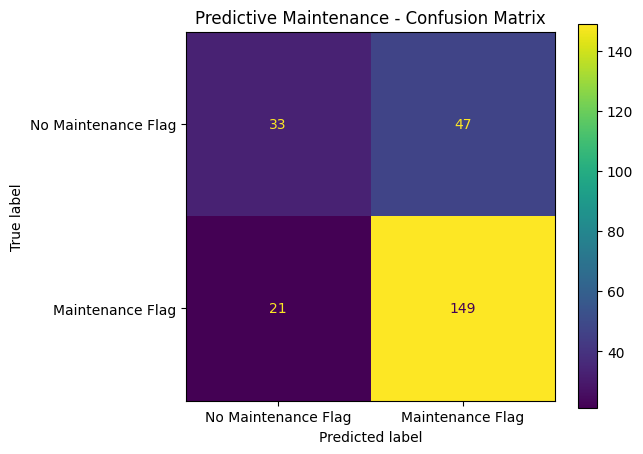


FEATURE IMPORTANCE:
             Feature  Importance
maintenance_days_ago    0.295826
     vibration_level    0.241560
     operating_hours    0.190099
      pressure_level    0.136852
         temperature    0.135663


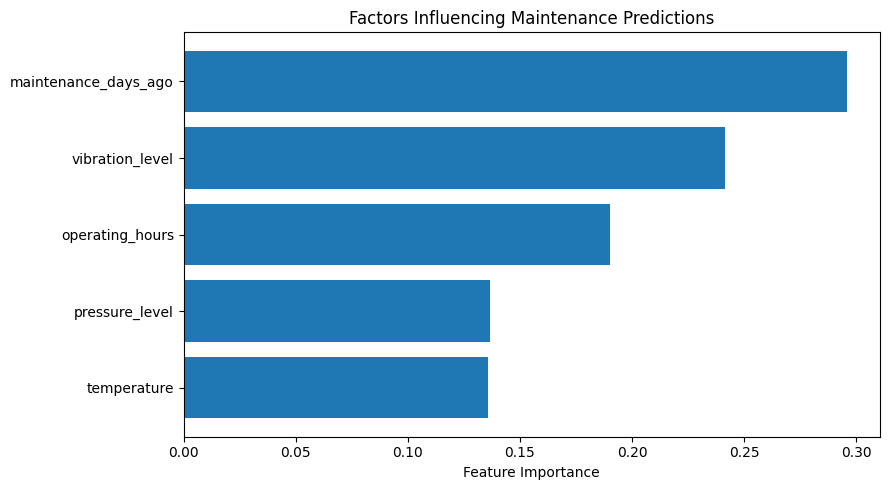


EQUIPMENT RISK SUMMARY:
risk_category
High      676
Low       254
Medium     70
Name: count, dtype: int64

TOP 15 EQUIPMENT RECORDS BY PREDICTED RISK:
 operating_hours  temperature  vibration_level  pressure_level  maintenance_days_ago  maintenance_risk risk_category                             recommended_action
        5081.049       73.856            4.834          57.973                   286               1.0          High Inspect equipment and assess maintenance needs
        5872.111       73.892            3.968          45.717                   255               1.0          High Inspect equipment and assess maintenance needs
        8103.134       52.173            3.599          43.111                   267               1.0          High Inspect equipment and assess maintenance needs
        8319.177       65.299            4.089          47.110                   333               1.0          High Inspect equipment and assess maintenance needs
        7433.609       80.60

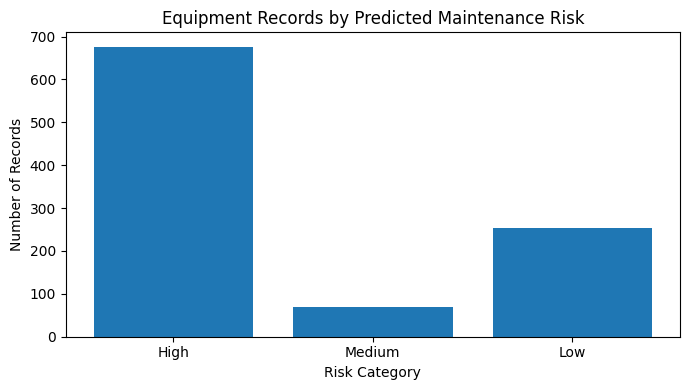


BUSINESS RECOMMENDATIONS:
1. Prioritize high-risk equipment for inspection.
2. Monitor temperature and vibration trends.
3. Review equipment with long gaps since maintenance.
4. Plan maintenance to reduce unexpected operational downtime.
5. Validate these predictions against real maintenance records.

DISCLAIMER:
This educational project uses synthetic data.
Predictions are not validated for real equipment or safety-critical use.


In [1]:

# PROJECT 9: PREDICTIVE MAINTENANCE FOR BUSINESS OPERATIONS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# 1. Generate sample equipment data
np.random.seed(42)
n = 1000

df = pd.DataFrame({
    "operating_hours": np.random.uniform(100, 10000, n),
    "temperature": np.random.normal(70, 12, n),
    "vibration_level": np.random.uniform(0.1, 5.0, n),
    "pressure_level": np.random.normal(50, 8, n),
    "maintenance_days_ago": np.random.randint(1, 365, n)
})

# 2. Create a simulated maintenance-failure outcome
risk_score = (
    -4.0
    + 0.00025 * df["operating_hours"]
    + 0.025 * (df["temperature"] - 65)
    + 0.65 * df["vibration_level"]
    + 0.012 * df["maintenance_days_ago"]
    + 0.015 * (df["pressure_level"] - 50)
)

probability = 1 / (1 + np.exp(-risk_score))
df["maintenance_required"] = (
    np.random.random(n) < probability
).astype(int)

print("Sample Equipment Data:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nMaintenance Outcome Counts:")
print(df["maintenance_required"].value_counts())

# 3. Prepare data for machine learning
X = df.drop(columns=["maintenance_required"])
y = df["maintenance_required"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# 4. Train the predictive model
model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# 5. Evaluate the model
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("\nMODEL PERFORMANCE")
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["No Maintenance Flag", "Maintenance Flag"],
    zero_division=0
))

# 6. Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["No Maintenance Flag", "Maintenance Flag"],
    values_format="d"
)
plt.title("Predictive Maintenance - Confusion Matrix")
plt.tight_layout()
plt.show()

# 7. Identify the most influential features
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nFEATURE IMPORTANCE:")
print(importance.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Factors Influencing Maintenance Predictions")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

# 8. Predict maintenance risk for all equipment records
df["maintenance_risk"] = model.predict_proba(X)[:, 1]

def classify_risk(score):
    if score >= 0.65:
        return "High"
    elif score >= 0.35:
        return "Medium"
    return "Low"

df["risk_category"] = df["maintenance_risk"].apply(classify_risk)

def recommend_action(category):
    if category == "High":
        return "Inspect equipment and assess maintenance needs"
    elif category == "Medium":
        return "Schedule an inspection and monitor operating conditions"
    return "Continue routine monitoring"

df["recommended_action"] = df["risk_category"].apply(recommend_action)

# 9. Summarize equipment risk
print("\nEQUIPMENT RISK SUMMARY:")
print(df["risk_category"].value_counts())

print("\nTOP 15 EQUIPMENT RECORDS BY PREDICTED RISK:")
print(
    df.sort_values("maintenance_risk", ascending=False)[
        [
            "operating_hours",
            "temperature",
            "vibration_level",
            "pressure_level",
            "maintenance_days_ago",
            "maintenance_risk",
            "risk_category",
            "recommended_action"
        ]
    ].head(15).round(3).to_string(index=False)
)

# 10. Visualize maintenance risk
risk_counts = df["risk_category"].value_counts().reindex(
    ["High", "Medium", "Low"], fill_value=0
)

plt.figure(figsize=(7, 4))
plt.bar(risk_counts.index, risk_counts.values)
plt.title("Equipment Records by Predicted Maintenance Risk")
plt.xlabel("Risk Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# 11. Business insights
print("\nBUSINESS RECOMMENDATIONS:")
print("1. Prioritize high-risk equipment for inspection.")
print("2. Monitor temperature and vibration trends.")
print("3. Review equipment with long gaps since maintenance.")
print("4. Plan maintenance to reduce unexpected operational downtime.")
print("5. Validate these predictions against real maintenance records.")

print("\nDISCLAIMER:")
print("This educational project uses synthetic data.")
print("Predictions are not validated for real equipment or safety-critical use.")
